# Examining the Main Research Question

The main research question is as follows: **'Are there differences in content between homosexual and heterosexual fan fiction published on Archive of Our Own as reflected through tags?'**

In [53]:
# Import package
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [25]:
df_metadata = pl.read_ndjson("./data/combined_metadata.jsonl") # Create the df_metadata DataFrame
df_metadata = df_metadata.unnest('metadata') # Turn the metadata column into 18 separate columns

fandoms = ["DC's Legends of Tomorrow (TV)", "Avatar: The Last Airbender (Cartoon 2005)", "Spider-Man: Spider-Verse (Sony Animated Movies)"]

# Select the target fandom and relationship categories
df_metadata = df_metadata.filter(
    ((pl.col("Fandom") == fandoms[0]) |
    (pl.col("Fandom") == fandoms[1]) |
    (pl.col("Fandom") == fandoms[2])) &
    ((pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M") |
    (pl.col("Category") == "F/M"))
)

df_metadata.head()

id,title,Additional Tags,Archive Warning,Category,Characters,Fandoms,Language,Rating,Relationship,author,chapters,completed,published,words,Fandom,Character,Collections,Series,Relationships
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""10012010""","""Just One Training""","""Explicit Sexual Content, Oral …","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""Explicit""","""Sara Lance/Leonard Snart""","""by capnwho""","""1/1""","""""","""2017-02-28""","""1,470""","""DC's Legends of Tomorrow (TV)""",null,null,"""Just One Fixation""",null
"""10013705""","""Five Months More""","""Established Relationship, surp…","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart""",null,"""English""","""Not Rated""",null,"""by flabbergabst""","""1/1""","""""","""2017-02-28""","""505""","""DC's Legends of Tomorrow (TV)""",null,null,"""The Captain Canary Collection""","""Sara Lance/Leonard Snart, Capt…"
"""10018964""","""It Ends with a Kiss""","""Alpha/Beta/Omega Dynamics, Min…","""No Archive Warnings Apply""","""M/M""","""Leonard Snart, Ray Palmer, Mic…",null,"""English""","""Teen And Up Audiences""","""Ray Palmer/Leonard Snart""","""by Constantsnow""","""1/1""","""""","""2017-02-28""","""3,008""","""DC's Legends of Tomorrow (TV)""",null,null,null,null
"""10030784""","""Bet""",null,"""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""General Audiences""","""Sara Lance/Leonard Snart""","""by orphan_account""","""1/1""","""""","""2017-03-01""","""1,273""","""DC's Legends of Tomorrow (TV)""",null,null,null,null
"""10033958""","""For the Both of Us""","""Captain Canary, ficcingcaptain…","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""Not Rated""",null,"""by flabbergabst""","""1/1""","""""","""2017-03-01""","""1,067""","""DC's Legends of Tomorrow (TV)""",null,null,"""The Captain Canary Collection""","""Sara Lance/Leonard Snart, Capt…"


In [ ]:
# Count the amount of fan works per fandom and category composition
ff_mm_amt = df_metadata.filter(
    (pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M")
).select(pl.len())
fm_amt = df_metadata.filter(pl.col("Category") == "F/M").select(pl.len())

print(f"""Homosexual Fan Works Amount: {ff_mm_amt}
Heterosexual Fan Works Amount: {fm_amt}""")

Homosexual Fan Works Amount: shape: (1, 1)
┌──────┐
│ len  │
│ ---  │
│ u32  │
╞══════╡
│ 5713 │
└──────┘
Heterosexual Fan Works Amount: shape: (1, 1)
┌──────┐
│ len  │
│ ---  │
│ u32  │
╞══════╡
│ 4256 │
└──────┘


## 1. Ratings

### 1.1 Creating the Ratings Dataset

In [155]:
df_ratings_ff_mm = df_metadata.filter(
    (pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M")
).select(pl.col("Rating").value_counts(sort=True)).unnest("Rating").rename({"count": "Homosexual Freq"}).with_columns((pl.col("Homosexual Freq") / ff_mm_amt.item(0,0) * 100).alias("Homosexual %")) # Filtered by F/F + M/M

df_ratings_fm = df_metadata.filter(
    (pl.col("Category") == "F/M")
).select(pl.col("Rating").value_counts(sort=True)).unnest("Rating").rename({"count": "Heterosexual Freq"}).with_columns((pl.col("Heterosexual Freq") / fm_amt.item(0,0) * 100).alias("Heterosexual %")) # Filtered by F/M

print(f"""Homosexual Ratings Amount: {df_ratings_ff_mm}
Heterosexual Ratings Amount: {df_ratings_fm}""")

Homosexual Ratings Amount: shape: (5, 3)
┌───────────────────────┬─────────────────┬──────────────┐
│ Rating                ┆ Homosexual Freq ┆ Homosexual % │
│ ---                   ┆ ---             ┆ ---          │
│ str                   ┆ u32             ┆ f64          │
╞═══════════════════════╪═════════════════╪══════════════╡
│ Teen And Up Audiences ┆ 1785            ┆ 31.24453     │
│ General Audiences     ┆ 1362            ┆ 23.840364    │
│ Explicit              ┆ 1175            ┆ 20.567128    │
│ Mature                ┆ 839             ┆ 14.685804    │
│ Not Rated             ┆ 552             ┆ 9.662174     │
└───────────────────────┴─────────────────┴──────────────┘
Heterosexual Ratings Amount: shape: (5, 3)
┌───────────────────────┬───────────────────┬────────────────┐
│ Rating                ┆ Heterosexual Freq ┆ Heterosexual % │
│ ---                   ┆ ---               ┆ ---            │
│ str                   ┆ u32               ┆ f64            │
╞══════════════

### 1.2 Visualizing the Ratings Dataset

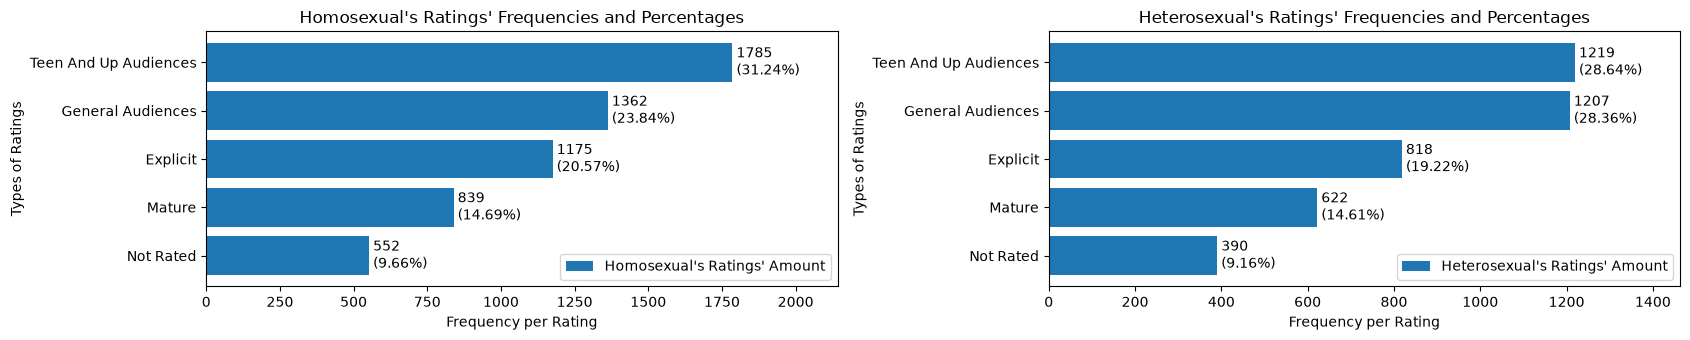

In [156]:
N = len(df_aw_ff_mm["Rating"]) # Amount of groups
width = 0.8 # Width of the bars
ind = np.arange(N) # Position of the bars on x-axis

fig, ax = plt.subplots(1, 2, figsize=(17, 3.5)) # Set figure size

# Plot a horizontal bar plot
p1 = ax[0].barh(ind, df_aw_ff_mm["Homosexual Freq"], width, label="Homosexual's Ratings' Amount")
p2 = ax[1].barh(ind, df_aw_fm["Heterosexual Freq"], width, label="Heterosexual's Ratings' Amount")

# Combine the Frequencies and %
ff_mm_labels = [
    f"{freq}\n({pct:.2f}%)"
    for freq, pct in zip(
        df_aw_ff_mm["Homosexual Freq"],
        df_aw_ff_mm["Homosexual %"]
    )
]

fm_labels = [
    f"{freq}\n({pct:.2f}%)"
    for freq, pct in zip(
        df_aw_fm["Heterosexual Freq"],
        df_aw_fm["Heterosexual %"]
    )
]

#labels
ax[0].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[0].set_xlabel('Frequency per Rating')
ax[0].set_title('Homosexual\'s Ratings\' Frequencies and Percentages')
ax[0].set_ylabel('Types of Ratings')
ax[0].set_yticks(ind)
ax[0].set_yticklabels(df_aw_ff_mm['Rating'])
ax[0].legend(loc='best')

ax[1].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[1].set_xlabel('Frequency per Rating')
ax[1].set_title('Heterosexual\'s Ratings\' Frequencies and Percentages')
ax[1].set_ylabel('Types of Ratings')
ax[1].set_yticks(ind)
ax[1].set_yticklabels(df_aw_fm['Rating'])
ax[1].legend(loc='best')

ax[0].bar_label(p1, labels=ff_mm_labels, padding=3)
ax[1].bar_label(p2, labels=fm_labels, padding=3)

# Add space for the labels
ax[0].set_xlim(right=df_aw_ff_mm["Homosexual Freq"].max() * 1.20)
ax[1].set_xlim(right=df_aw_fm["Heterosexual Freq"].max() * 1.20)

plt.tight_layout()
plt.show()

## 2. Archive Warnings

### 2.1 Creating the Archive Warnings Dataset

In [135]:
df_aw_ff_mm = df_metadata.filter(
    (pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M")
).select(pl.col("Archive Warning").value_counts(sort=True)).unnest("Archive Warning").drop_nulls().rename({"count": "Homosexual Freq"}).with_columns((pl.col("Homosexual Freq") / ff_mm_amt.item(0,0) * 100).alias("Homosexual %")) # Filtered by F/F + M/M

df_aw_fm = df_metadata.filter(
    (pl.col("Category") == "F/M")
).select(pl.col("Archive Warning").value_counts(sort=True)).unnest("Archive Warning").drop_nulls().rename({"count": "Heterosexual Freq"}).with_columns((pl.col("Heterosexual Freq") / fm_amt.item(0,0) * 100).alias("Heterosexual %")) # Filtered by F/M

print(f"""Homosexual Archive Warnings Amount: {df_aw_ff_mm}
Heterosexual Archive Warnings Amount: {df_aw_fm}""")

Homosexual Archive Warnings Amount: shape: (6, 3)
┌─────────────────────────────────┬─────────────────┬──────────────┐
│ Archive Warning                 ┆ Homosexual Freq ┆ Homosexual % │
│ ---                             ┆ ---             ┆ ---          │
│ str                             ┆ u32             ┆ f64          │
╞═════════════════════════════════╪═════════════════╪══════════════╡
│ No Archive Warnings Apply       ┆ 3053            ┆ 53.439524    │
│ Creator Chose Not To Use Archi… ┆ 1722            ┆ 30.141782    │
│ Underage Sex                    ┆ 268             ┆ 4.691055     │
│ Graphic Depictions Of Violence  ┆ 168             ┆ 2.940662     │
│ Major Character Death           ┆ 88              ┆ 1.540347     │
│ Rape/Non-Con                    ┆ 48              ┆ 0.840189     │
└─────────────────────────────────┴─────────────────┴──────────────┘
Heterosexual Archive Warnings Amount: shape: (6, 3)
┌─────────────────────────────────┬───────────────────┬───────────────

### 2.2 Visualizing the Archive Warnings Dataset

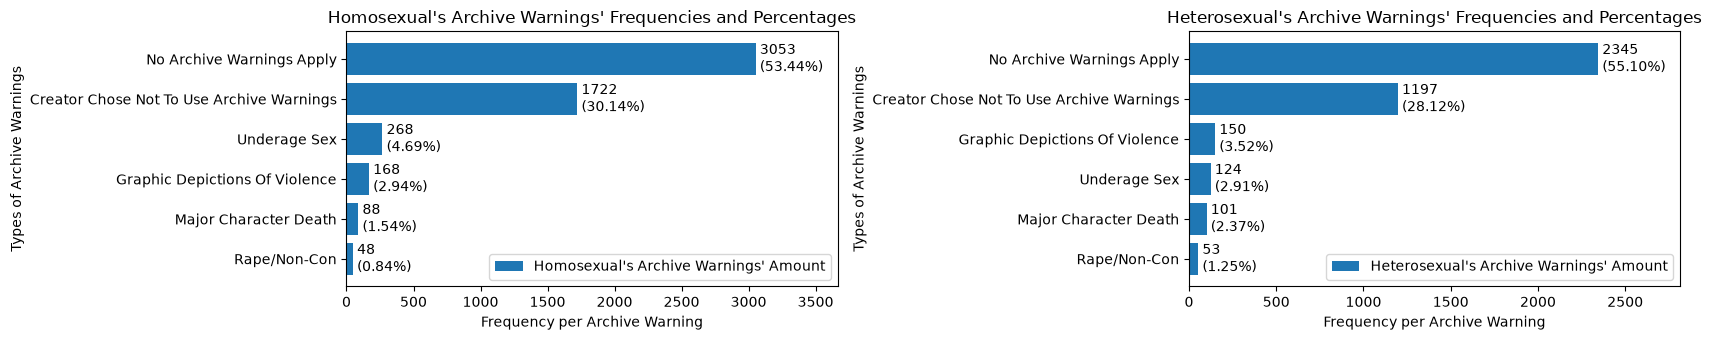

In [144]:
N = len(df_aw_ff_mm["Archive Warning"]) # Amount of groups
width = 0.8 # Width of the bars
ind = np.arange(N) # Position of the bars on x-axis

fig, ax = plt.subplots(1, 2, figsize=(17, 3.5)) # Set figure size

# Plot a horizontal bar plot
p1 = ax[0].barh(ind, df_aw_ff_mm["Homosexual Freq"], width, label="Homosexual's Archive Warnings' Amount")
p2 = ax[1].barh(ind, df_aw_fm["Heterosexual Freq"], width, label="Heterosexual's Archive Warnings' Amount")

# Combine the Frequencies and %
ff_mm_labels = [
    f"{freq}\n({pct:.2f}%)"
    for freq, pct in zip(
        df_aw_ff_mm["Homosexual Freq"],
        df_aw_ff_mm["Homosexual %"]
    )
]

fm_labels = [
    f"{freq}\n({pct:.2f}%)"
    for freq, pct in zip(
        df_aw_fm["Heterosexual Freq"],
        df_aw_fm["Heterosexual %"]
    )
]

#labels
ax[0].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[0].set_xlabel('Frequency per Archive Warning')
ax[0].set_title('Homosexual\'s Archive Warnings\' Frequencies and Percentages')
ax[0].set_ylabel('Types of Archive Warnings')
ax[0].set_yticks(ind)
ax[0].set_yticklabels(df_aw_ff_mm['Archive Warning'])
ax[0].legend(loc='best')

ax[1].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[1].set_xlabel('Frequency per Archive Warning')
ax[1].set_title('Heterosexual\'s Archive Warnings\' Frequencies and Percentages')
ax[1].set_ylabel('Types of Archive Warnings')
ax[1].set_yticks(ind)
ax[1].set_yticklabels(df_aw_fm['Archive Warning'])
ax[1].legend(loc='best')

ax[0].bar_label(p1, labels=ff_mm_labels, padding=3)
ax[1].bar_label(p2, labels=fm_labels, padding=3)

# Add space for the labels
ax[0].set_xlim(right=df_aw_ff_mm["Homosexual Freq"].max() * 1.20)
ax[1].set_xlim(right=df_aw_fm["Heterosexual Freq"].max() * 1.20)

plt.tight_layout()
plt.show()

## 3. Additional Tags

### 3.1 Creating the Additional Tags Dataset

### 3.2 Visualizing the Additional Tags Dataset